# 02 EDA

Exploratory analysis of food access and frequent mental distress (`MHLTH`) across census tracts.

Data: `data/processed/tract_health_food_access_2019.csv` (built in `01_DataProcessing`): CDC PLACES 2021 release
(2019 survey data) merged with the USDA Food Access Research Atlas (2019 stores; 2010 Census; ACS 2014-18).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import plotly.express as px

from ac209a import build_dataset as bd

## Load data

The processed file has one row per tract **and** health measure (`MHLTH`, `DEPRESSION`), so each tract appears twice in `df`.

- `df`: all rows. Use it only for plots that compare the two health measures (one row per tract within each measure).
- `tracts`: **one row per tract** (the `MHLTH` rows; the food access and tract columns are the same on every measure row).
  Use it for every count, distribution, correlation and scatter, so each tract is counted once and `Data_Value` is mental distress.

In [2]:
df = pd.read_csv(bd.OUTPUT_FILE, dtype={"GEOID": str})
df["Area"] = df["Urban"].map({1: "Urban", 0: "Rural"})            # label for plots

# One row per tract: the MHLTH rows (outcome = frequent mental distress)
tracts = df[df["MeasureId"] == "MHLTH"].copy()
assert tracts["GEOID"].is_unique, "tracts should have one row per GEOID"

print(f"df: {len(df):,} rows (tract x measure)  ->  tracts: {len(tracts):,} unique tracts")
tracts["Area"].value_counts()

df: 140,666 rows (tract x measure)  ->  tracts: 70,333 unique tracts


Area
Urban    53191
Rural    17142
Name: count, dtype: int64

In [3]:
tracts

,GEOID,State,StateAbbr,County,Geolocation,Urban,MeasureId,Year,Data_Value,Data_Value_Unit,...,lahunv1share,lahunv10share,Pop2010,OHU2010,PovertyRate,MedianFamilyIncome,TractSeniors,TractHUNV,TractSNAP,Area
1,01001020100,Alabama,AL,Autauga County,POINT (-86.49001486 32.47718251),1,MHLTH,2019,17.4,%,...,0.792272,NaN,1912,693,11.336453,81250.0,221.0,6.0,102.0,Urban
3,01001020200,Alabama,AL,Autauga County,POINT (-86.47338874 32.47425254),1,MHLTH,2019,18.5,%,...,9.004514,NaN,2170,743,17.876788,49000.0,214.0,89.0,156.0,Urban
5,01001020300,Alabama,AL,Autauga County,POINT (-86.4602024 32.47543618),1,MHLTH,2019,18.1,%,...,0.000000,NaN,3373,1256,15.046030,62609.0,439.0,99.0,172.0,Urban
7,01001020400,Alabama,AL,Autauga County,POINT (-86.44370417 32.47203959),1,MHLTH,2019,14.3,%,...,0.461172,NaN,4386,1722,2.845210,70607.0,904.0,21.0,98.0,Urban
9,01001020500,Alabama,AL,Autauga County,POINT (-86.42271039 32.45891625),1,MHLTH,2019,15.4,%,...,1.352569,NaN,10766,4082,15.150891,96334.0,1126.0,230.0,339.0,Urban
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140657,56043000200,Wyoming,WY,Washakie County,POINT (-107.6820163 43.90461668),0,MHLTH,2019,12.4,%,...,2.563461,0.505403,3326,1317,9.729551,67254.0,593.0,61.0,64.0,Rural
140659,56043000301,Wyoming,WY,Washakie County,POINT (-107.956403 44.01436029),1,MHLTH,2019,13.8,%,...,NaN,NaN,2665,1154,11.583333,64152.0,399.0,88.0,41.0,Urban
140661,56043000302,Wyoming,WY,Washakie County,POINT (-107.949451 44.0275357),1,MHLTH,2019,12.9,%,...,0.261754,NaN,2542,1021,16.328963,69605.0,516.0,23.0,64.0,Urban
140663,56045951100,Wyoming,WY,Weston County,POINT (-104.5735492 43.84016153),0,MHLTH,2019,13.5,%,...,0.999730,0.185807,3314,1322,17.460846,74500.0,499.0,47.0,34.0,Rural


## Urban vs Rural tracts

How the tracts split between urban and rural.

In [4]:
# Count unique tracts (tracts already has one row per GEOID)
area_counts = tracts["Area"].value_counts().rename_axis("Area").reset_index(name="Tracts")
area_counts["Share"] = area_counts["Tracts"] / area_counts["Tracts"].sum()

fig = px.bar(area_counts, x="Area", y="Tracts", color="Area",
             color_discrete_map={"Urban": "#2a78d6", "Rural": "#eb6834"},
             text=area_counts.apply(lambda r: f"{r['Tracts']:,} ({r['Share']:.0%})", axis=1),
             title="Census tracts by urban/rural status")
fig.update_layout(showlegend=False)
fig.show()


In [5]:
import plotly.express as px

# Share of each state's residents living in urban vs rural tracts (USDA urban flag, 2010 population)
t = tracts.assign(rural_pop=tracts["Pop2010"] * (tracts["Urban"] == 0))
st = t.groupby("StateAbbr").agg(pop=("Pop2010", "sum"), rural_pop=("rural_pop", "sum"),
                                urban_tracts=("Urban", lambda u: (u == 1).sum()),
                                rural_tracts=("Urban", lambda u: (u == 0).sum())).reset_index()
st["% rural"] = st["rural_pop"] / st["pop"] * 100
st["% urban"] = 100 - st["% rural"]

fig = px.choropleth(st, locations="StateAbbr", locationmode="USA-states", scope="usa",
                    color="% urban", color_continuous_scale=["#eb6834", "#f0efec", "#2a78d6"],   # orange = rural, blue = urban
                    range_color=[30, 100],
                    hover_name="StateAbbr",
                    hover_data={"StateAbbr": False, "% urban": ":.0f", "% rural": ":.0f",
                                "urban_tracts": ":,", "rural_tracts": ":,"},
                    labels={"urban_tracts": "Urban tracts", "rural_tracts": "Rural tracts"},
                    title="Share of residents living in urban tracts, by state (USDA urban/rural flag; NJ not in data)")
fig.update_traces(marker_line_color="white", marker_line_width=0.5)

# On-map labels: state, % urban, and urban / rural tract counts
def short(n):
    return f"{n / 1000:.1f}k" if n >= 1000 else f"{n}"

def label(row, sep):
    return f"<b>{row.StateAbbr}</b> {row['% urban']:.0f}%{sep}{short(row.urban_tracts)}/{short(row.rural_tracts)}"

# Small Northeast states: shorter, smaller labels so they fit on the map (counts are in the hover)
small = ["VT", "NH", "MA", "RI", "CT", "DE", "MD", "DC"]
big = st[~st["StateAbbr"].isin(small)]
tiny = st[st["StateAbbr"].isin(small)]
fig.add_scattergeo(locations=big["StateAbbr"], locationmode="USA-states",
                   text=[label(r, "<br>") for _, r in big.iterrows()], mode="text",
                   textfont=dict(size=8, color="#0b0b0b"), hoverinfo="skip", showlegend=False)
fig.add_scattergeo(locations=tiny["StateAbbr"], locationmode="USA-states",
                   text=[f"<b>{r.StateAbbr}</b> {r['% urban']:.0f}%" for _, r in tiny.iterrows()], mode="text",
                   textfont=dict(size=6, color="#0b0b0b"), hoverinfo="skip", showlegend=False)

fig.update_layout(width=1150, height=650, margin=dict(l=10, r=10, t=60, b=40),
                  coloraxis_colorbar=dict(title="% urban", ticksuffix="%"))
fig.add_annotation(text="Labels: state, % of residents in urban tracts; urban / rural tract counts "
                        "(small Northeast states: % only; hover for counts)",
                   x=0.5, y=-0.04, xref="paper", yref="paper", showarrow=False, font=dict(size=11, color="#52514e"))
fig.show()


The sample is 70,333 tracts in 49 states plus DC (New Jersey has no mental distress data in this release).
Three-quarters are urban (53,191; 76%) and one-quarter rural (17,142; 24%). Urban tracts dominate any pooled ("all tracts") result,
so urban and rural are also examined separately throughout.

In [6]:
import numpy as np
from plotly.subplots import make_subplots

colors = {"Urban": "#2a78d6", "Rural": "#eb6834"}
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.08,
                    subplot_titles=["Frequent mental distress by urban / rural",
                                    "Uncertainty: width of each tract's 95% confidence interval"])

# Left: distribution of mental distress, urban vs rural, with mean line and stats per group
for i, (area, color) in enumerate(colors.items()):
    values = tracts.loc[tracts["Area"] == area, "Data_Value"]
    mean, skew = values.mean(), values.skew()
    fig.add_histogram(x=values, name=area, marker_color=color, opacity=0.6, nbinsx=100,
                      histnorm="probability density", row=1, col=1)
    fig.add_vline(x=mean, line_color=color, line_dash="dash", line_width=2, row=1, col=1)   # mean line
    fig.add_annotation(x=0.44, y=0.95 - 0.08 * i, xref="paper", yref="paper", xanchor="right", showarrow=False,
                       text=f"<b>{area}</b>: mean {mean:.1f}%, skewness {skew:+.2f}", font=dict(color=color, size=12))

# Right: distribution of confidence interval widths, with mean line and +/- 1 SD band
ci_width = tracts["High_Confidence_Limit"] - tracts["Low_Confidence_Limit"]
mean, sd = ci_width.mean(), ci_width.std()
fig.add_histogram(x=ci_width, marker_color="#4C72B0", opacity=0.8, xbins=dict(start=0, end=10, size=0.2),
                  showlegend=False, row=1, col=2)
fig.add_vrect(x0=mean - sd, x1=mean + sd, fillcolor="#DD8452", opacity=0.15, line_width=0, row=1, col=2)  # +/- 1 SD
fig.add_vline(x=mean, line_color="#DD8452", line_width=2.5, row=1, col=2)                                 # mean
fig.add_annotation(x=0.98, y=0.95, xref="paper", yref="paper", xanchor="right", showarrow=False,
                   text=f"Mean {mean:.2f} pts, SD {sd:.2f}<br>±1 SD: {mean - sd:.1f} to {mean + sd:.1f}",
                   font=dict(color="#a63603", size=12))

fig.update_layout(barmode="overlay", template="simple_white", width=1300, height=480,
                  title="Frequent mental distress across census tracts and the uncertainty in its estimates (2019)",
                  legend=dict(x=0.3, y=0.75))
fig.update_xaxes(title_text="Frequent mental distress (% of adults)", row=1, col=1)
fig.update_xaxes(title_text="CI width (percentage points)", range=[0, 10], row=1, col=2)
fig.update_yaxes(title_text="Density", row=1, col=1)
fig.update_yaxes(title_text="Tracts", row=1, col=2)
fig.show()


Urban and rural tracts have similar average mental distress. Means are 15.1% urban and 15.6% rural. Rural is about half a point higher: a real difference at this sample size, but small. Urbanicity alone doesn't separate mental distress much, which is why the analysis moves on to poverty and access.

Most tracts fall in a fairly narrow range. The bulk is roughly 10–20%, peaking around 14–15%. Mental distress varies between neighborhoods, but not wildly. That's the variation the model has to explain.

Both distributions have a right tail, and it's longer in urban tracts (skewness +0.75 vs +0.53). A minority of tracts, mostly urban, have much higher distress (25–35%). From the earlier plots, these tend to be high-poverty urban neighborhoods. The rural distribution is more compact: fewer extremes in either direction.

## Correlation matrix

Pairwise Pearson correlations between the outcome, the poverty/income controls and the food access measures,
computed separately for urban and rural tracts. Each pair uses the tracts where both columns are present.

In [7]:
import numpy as np

labels = {
    "Data_Value": "Mental distress",
    "PovertyRate": "Poverty rate",
    "MedianFamilyIncome": "Median family income",
    "lapophalfshare": "% beyond 1/2 mi",
    "lapop1share": "% beyond 1 mi",
    "lapop10share": "% beyond 10 mi",
    "lahunvhalfshare": "No vehicle & >1/2 mi",
    "lahunv1share": "No vehicle & >1 mi",
    "lahunv10share": "No vehicle & >10 mi",
    "LA1and10": "Low-access flag",
    "LILATracts_1And10": "Food desert flag",
}
groups = {
    "All tracts": tracts,
    "Urban": tracts[tracts["Area"] == "Urban"],
    "Rural": tracts[tracts["Area"] == "Rural"],
}

# One correlation matrix per group, stacked so plotly can draw them side by side
corrs = [g[list(labels)].corr() for g in groups.values()]

fig = px.imshow(np.stack(corrs), facet_col=0, x=list(labels.values()), y=list(labels.values()),
                text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                width=1900, height=650,
                title="Correlations: mental distress, poverty and food access")
for i, name in enumerate(groups):                              # facet titles: "All tracts", "Urban", "Rural"
    fig.layout.annotations[i].text = name
fig.update_xaxes(tickangle=-40)
fig.show()


## Defining Food Access

The 2019 USDA Food Access Research Atlas defines food access in terms of **distance to the nearest supermarket, supercenter or
large grocery store**. USDA allocates each tract's 2010 Census population to ½-kilometer grid cells, computes the straight-line
distance from each cell to the nearest qualifying store, and reports the share of residents living beyond fixed thresholds
(½, 1, 10 and 20 miles). A parallel set of measures restricts the count to **housing units without a vehicle** (ACS 2014–18),
capturing households for whom distance is a practical barrier.

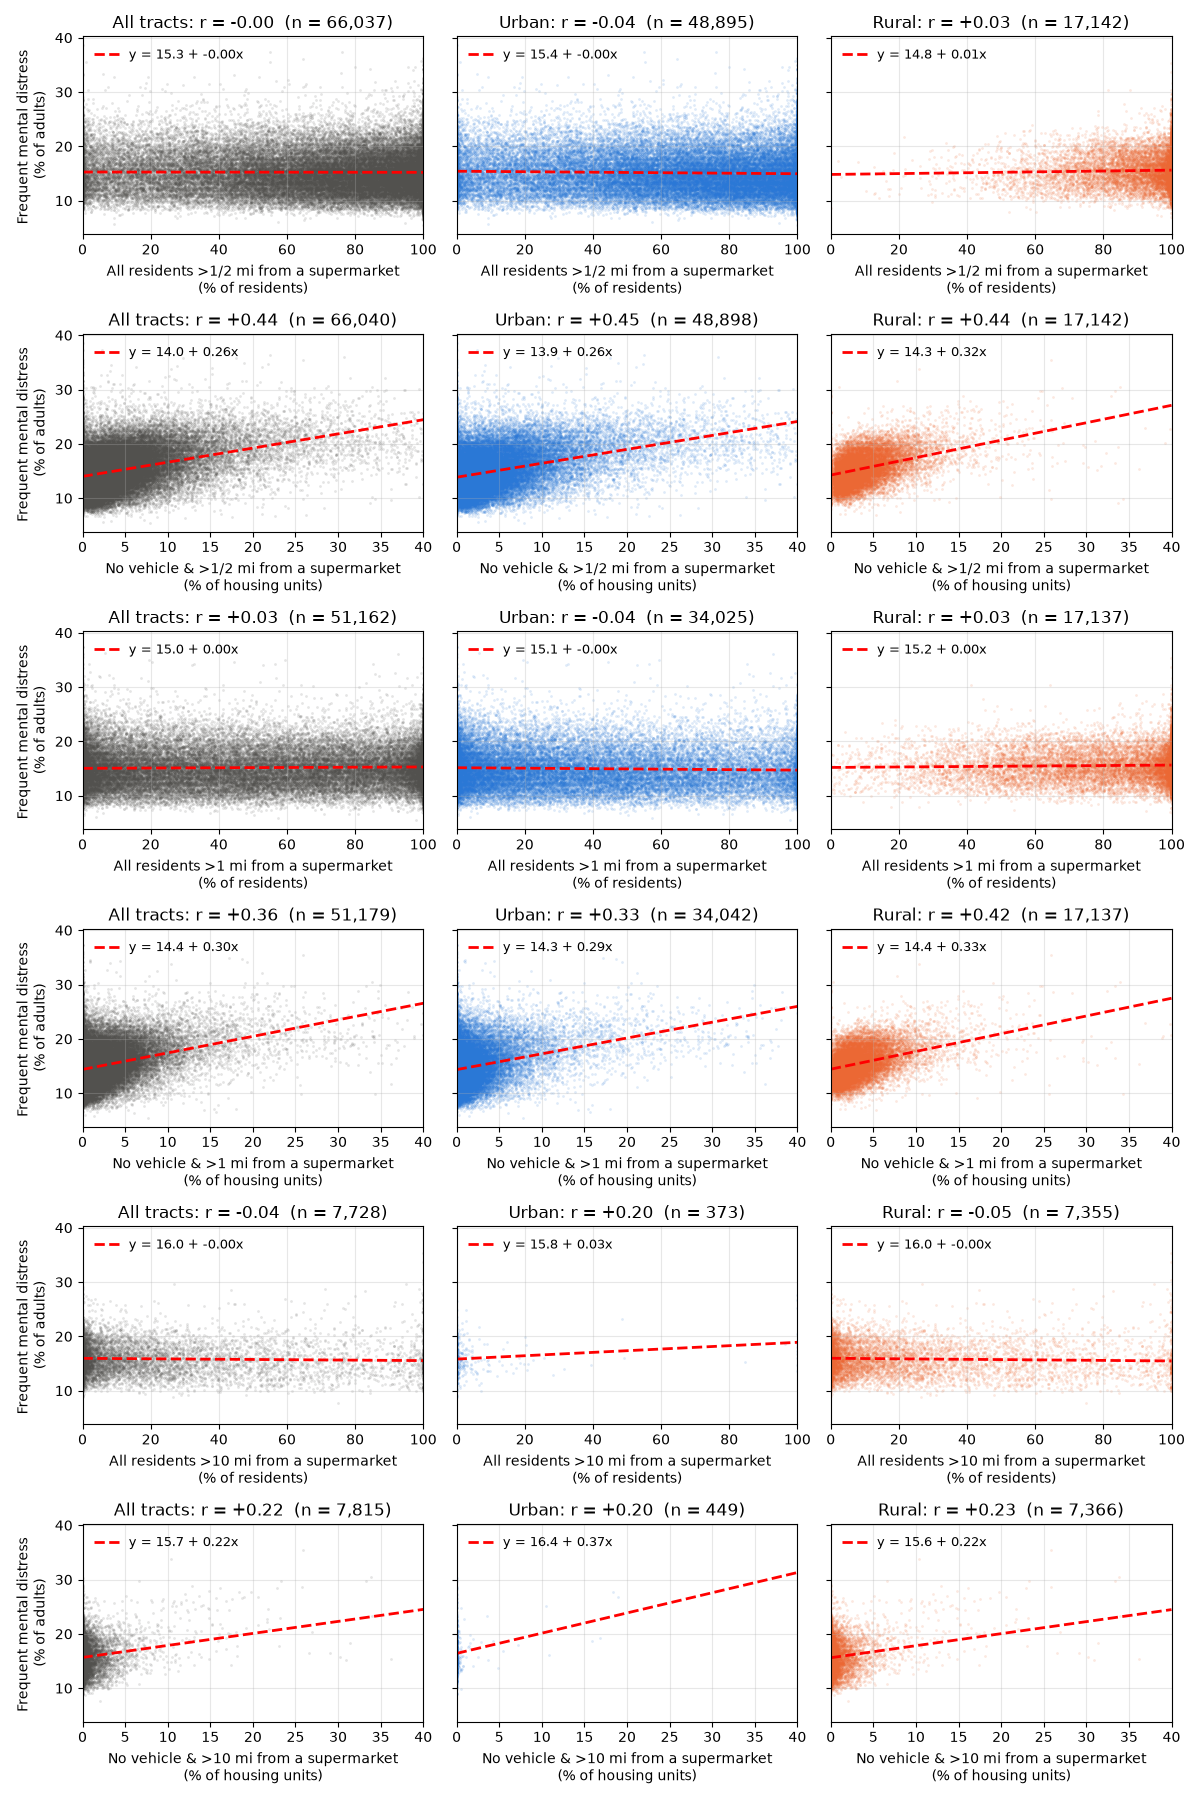

In [8]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

measures = {   # column: (axis label, x-axis max), ordered by distance; each distance with and without a car
    "lapophalfshare":  ("All residents >1/2 mi from a supermarket\n(% of residents)", 100),
    "lahunvhalfshare": ("No vehicle & >1/2 mi from a supermarket\n(% of housing units)", 40),
    "lapop1share":     ("All residents >1 mi from a supermarket\n(% of residents)", 100),
    "lahunv1share":    ("No vehicle & >1 mi from a supermarket\n(% of housing units)", 40),
    "lapop10share":    ("All residents >10 mi from a supermarket\n(% of residents)", 100),
    "lahunv10share":   ("No vehicle & >10 mi from a supermarket\n(% of housing units)", 40),
}

colors = {"All tracts": "#52514e", "Urban": "#2a78d6", "Rural": "#eb6834"}

fig, axes = plt.subplots(len(measures), 3, figsize=(12, 3 * len(measures)), sharey=True)
for row, (x, (xlabel, xmax)) in zip(axes, measures.items()):
    d = tracts.dropna(subset=[x])
    groups = {"All tracts": d, "Urban": d[d["Area"] == "Urban"], "Rural": d[d["Area"] == "Rural"]}
    for ax, (name, s) in zip(row, groups.items()):
        sns.scatterplot(data=s, x=x, y="Data_Value", color=colors[name], s=4, alpha=0.15, linewidth=0, ax=ax)

        # Simple linear fit (least squares)
        slope, intercept = np.polyfit(s[x], s["Data_Value"], 1)
        xs = np.array([0, xmax])
        ax.plot(xs, intercept + slope * xs, color="r", linewidth=2, linestyle="--",
                label=f"y = {intercept:.1f} + {slope:.2f}x")
        ax.legend(loc="upper left", frameon=False, fontsize=9)

        ax.set_title(f"{name}: r = {s[x].corr(s['Data_Value']):+.2f}  (n = {len(s):,})")
        ax.set_xlim(0, xmax)
        ax.set_xlabel(xlabel)
        ax.grid(True, alpha=0.3)
    row[0].set_ylabel("Frequent mental distress \n(% of adults)")

fig.tight_layout()
plt.show()


The six rows of distance plots answer the "Defining Food Access" question clearly: **distance alone doesn't relate to mental distress; distance without a means of transportation does.**

Distance alone is flat at every threshold. The "all residents" rows are shapeless with flat fitted lines. Whether 10% or 90% of residents live far from a supermarket, mental distress is about the same. Most people who live far from a store have a car, so the distance isn't a real barrier for them. In contrast, distance without a car slopes upward at every threshold. Tracts with more car-less households far from a store have higher mental distress. That holds in urban and rural tracts.

The no-vehicle relationship weakens as the distance grows (+0.44 → +0.36 → +0.22). Two reasons:

Fewer tracts and less variation: almost no one lives 10 miles from a store without a car, so the 10-mile measure is mostly near zero and covers only about 7,800 tracts.
½ mile catches more of the barrier: without a car, even half a mile is a real obstacle, especially in cities, so the broadest definition captures the most affected households.
Urban vs rural:

At ½ mile the relationship is equally strong in both (+0.45 / +0.44).
At 1 mile it's stronger in rural tracts (+0.42 vs +0.33).
The urban 10-mile panels rest on only a few hundred tracts, so they're unreliable.
The "all residents" distributions show the urban/rural split seen earlier: rural tracts pile up near 100% (almost everyone is far), urban tracts spread across the range. Distance alone mostly tells you whether a tract is rural, not how distressed it is.

**Limitation:**
- **Raw associations only.** Poverty is not controlled for. Car-less households are concentrated in poorer tracts
  (poverty vs no vehicle & >½ mi: r ≈ +0.5), so part of the upward slope in the no-vehicle rows reflects poverty.
- **Different units.** The "all residents" measures are shares of **people**; the no-vehicle measures are shares of
  **housing units**. The two rows at each distance are not directly comparable in level.
    How access is measured. The USDA measures straight-line distance to the nearest supermarket, supercenter, or large grocery store. Our primary measure is the share of housing units that lack a vehicle and are more than half a mile from one of these stores. It does not capture travel time, transit options, food prices, or access to smaller stores. The estimates combine 2019 store locations, 2010 Census population and housing counts, and 2014–2018 ACS vehicle availability data, so the inputs reflect different periods.

    That matters most in tracts where housing or vehicle access changed substantially before 2019. For example, if many homes were built near a supermarket after 2010, the measure could understate how many households lived close to it in 2019. The direction of the error can vary by tract.

    - Can we still use it to study the association with 2019 mental distress?

- **Tract-level, not individual.** These describe neighborhoods; they do not show that a given person's access
  affects their own mental health, and they do not establish causation.


## Accounting for Poverty

“Beyond poverty” means asking whether supermarket access is associated with mental distress after accounting for a neighborhood’s poverty rate. Poverty is the strongest correlate of frequent mental distress, and it is also associated with food access. It is therefore a potential **confounder**: part of the observed relationship between food access and mental distress may simply reflect poverty. This section evaluates that in four steps.

1. How strongly is poverty associated with ...
    - mental distress?
    - food access?
2. How do mental distress and food access vary across poverty levels?
4. Is food access still associated with mental distress among tracts with similar poverty?

Steps 1 and 2 establish whether poverty meets the conditions of a confounder (associated with both the outcome and the predictor).
Steps 3 and 4 hold poverty approximately constant by comparing tracts within the same poverty band, a coarse version of the
adjustment performed later in the regression models.

**Poverty bands.** We group census tracts the poverty rates using the [USDA Economic Research Service’s poverty area thresholds](https://ers.usda.gov/data-products/poverty-area-measures). These bands let us explore whether limited supermarket access is associated with frequent mental distress among tracts with broadly similar poverty rates. Poverty still varies within the ranges, so this is a rough comparison.

| Band | Poverty rate | Definition |
|---|---|---|
| Below high poverty | < 20% | Does not meet the high-poverty threshold |
| High poverty | 20% to < 40% | Poverty rate of 20.0% or more |
| Extreme poverty | ≥ 40% | Poverty rate of 40.0% or more |


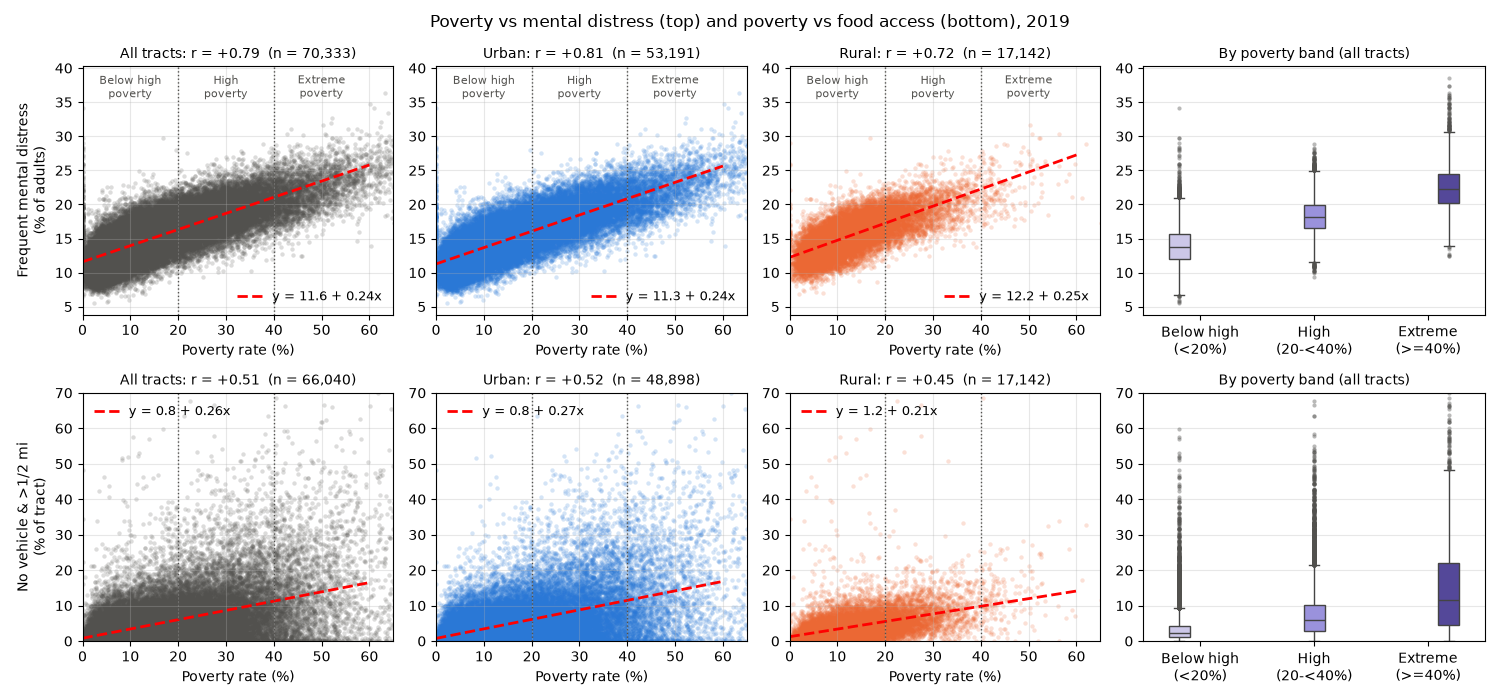

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

colors = {"All tracts": "#52514e", "Urban": "#2a78d6", "Rural": "#eb6834"}
bands = ["Below high\n(<20%)", "High\n(20-<40%)", "Extreme\n(>=40%)"]
band_colors = ["#c8c1ee", "#9085e9", "#4a3aa7"]   # light -> dark purple by poverty level (distinct from urban/rural colors)
tracts["Poverty band"] = pd.cut(tracts["PovertyRate"], bins=[0, 20, 40, float("inf")], right=False, labels=bands)

rows = [   # (y column, y-axis label)
    ("Data_Value", "Frequent mental distress\n(% of adults)"),
    ("lahunvhalfshare", "No vehicle & >1/2 mi\n(% of tract)"),
]

# Outlier dots: small, semi-transparent, dark gray so they show against the white background
outliers = dict(marker="o", markersize=3, alpha=0.4, markerfacecolor="#52514e", markeredgewidth=0)

fig, axes = plt.subplots(2, 4, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
for i, (row, (yc, ylabel)) in enumerate(zip(axes, rows)):
    d = tracts.dropna(subset=["PovertyRate", yc])
    groups = {"All tracts": d, "Urban": d[d["Area"] == "Urban"], "Rural": d[d["Area"] == "Rural"]}

    # Columns 1-3: poverty rate vs the variable, all / urban / rural, with a linear fit
    for ax, (name, s) in zip(row[:3], groups.items()):
        sns.scatterplot(data=s, x="PovertyRate", y=yc, color=colors[name], s=10, alpha=0.2, linewidth=0, ax=ax)
        
        slope, intercept = np.polyfit(s["PovertyRate"], s[yc], 1)
        xs = np.array([0, 60])
        ax.plot(xs, intercept + slope * xs, color="red", linewidth=2, linestyle="--",
                label=f"y = {intercept:.1f} {'+' if slope >= 0 else '-'} {abs(slope):.2f}x")
        ax.legend(loc="lower right" if i == 0 else "upper left", frameon=False, fontsize=9)   # avoid covering the dots

        # Poverty thresholds: dotted lines at 20% and 40%, band names between them (top row only)
        for x in (20, 40):
            ax.axvline(x, color="#52514e", linewidth=1, linestyle=":")
        if i == 0:
            for x_mid, text in [(10, "Below high\npoverty"), (30, "High\npoverty"), (50, "Extreme\npoverty")]:
                ax.text(x_mid, 0.97, text, transform=ax.get_xaxis_transform(),
                        ha="center", va="top", fontsize=8, color="#52514e")

        ax.set_title(f"{name}: r = {s['PovertyRate'].corr(s[yc]):+.2f}  (n = {len(s):,})", fontsize=10)
        ax.set(xlim=(0, 65), xlabel="Poverty rate (%)", ylabel="")
        ax.grid(True, alpha=0.3)
    row[0].set_ylabel(ylabel)
    for ax in row[1:3]:
        ax.sharey(row[0])

    # Column 4: distribution of the variable within each poverty band, colored by band, with outliers shown
    ax = row[3]
    sns.boxplot(data=d, x="Poverty band", y=yc, order=bands, hue="Poverty band", hue_order=bands,
                palette=band_colors, legend=False, width=0.55,
                showfliers=True, flierprops=outliers, ax=ax)
    ax.sharey(row[0])
    ax.set(xlabel="", ylabel="", title="By poverty band (all tracts)")
    ax.title.set_fontsize(10)
    ax.grid(True, axis="y", alpha=0.3)

axes[1, 0].set_ylim(0, 70)
fig.suptitle("Poverty vs mental distress (top) and poverty vs food access (bottom), 2019")
fig.tight_layout()
plt.show()


In 2019, census tracts with higher poverty rates tended to have higher estimated rates of frequent mental distress (top row, \(r = 0.79\) overall). They also tended to have a larger share of households that lacked a vehicle and lived more than half a mile from a supermarket (bottom row, \(r = 0.51\) overall). Both patterns appeared in urban and rural tracts. Because poverty is associated with both measures, differences in poverty could account for part of the observed relationship between limited supermarket access and mental distress. This motivates comparing tracts within poverty bands and adjusting for the continuous poverty rates for the project.

Together, the panels show how each measure varies across poverty levels.

In [10]:
def access_band_grid(x, label):
    """3x3 grid: rows = all / urban / rural tracts, columns = poverty bands; scatter + linear fit."""
    bands = ["Below high poverty (<20%)", "High poverty (20-<40%)", "Extreme poverty (>=40%)"]
    colors = {"All tracts": "#52514e", "Urban": "#2a78d6", "Rural": "#eb6834"}

    d = tracts.dropna(subset=[x]).copy()
    d["Poverty band"] = pd.cut(d["PovertyRate"], bins=[0, 20, 40, float("inf")], right=False, labels=bands)
    areas = {"All tracts": d, "Urban": d[d["Area"] == "Urban"], "Rural": d[d["Area"] == "Rural"]}

    fig, axes = plt.subplots(3, 3, figsize=(14, 8), sharex=True, sharey=True)
    for row, (area, a) in zip(axes, areas.items()):
        for ax, band in zip(row, bands):
            s = a[a["Poverty band"] == band]
            sns.scatterplot(data=s, x=x, y="Data_Value", color=colors[area],
                            s=10, alpha=0.2, linewidth=0, ax=ax)

            # Simple linear fit (least squares)
            slope, intercept = np.polyfit(s[x], s["Data_Value"], 1)
            xs = np.array([0, 40])
            ax.plot(xs, intercept + slope * xs, color="r", linewidth=2, linestyle="--",
                    label=f"y = {intercept:.1f} + {slope:.2f}x")
            ax.legend(loc="upper left", frameon=False, fontsize=9)

            ax.set_title(f"{area} | {band}\nr = {s[x].corr(s['Data_Value']):+.2f}  (n = {len(s):,})", fontsize=10)
            ax.set_xlim(0, 40)
            ax.grid(True, alpha=0.3)
        row[0].set_ylabel("Frequent mental distress\n(% of adults)")
    for ax in axes[-1]:
        ax.set_xlabel(f"{label}\n(% of tract)")
    fig.suptitle(f"Frequent mental distress vs {label.lower()}, within poverty bands (2019)")
    fig.tight_layout()
    plt.show()


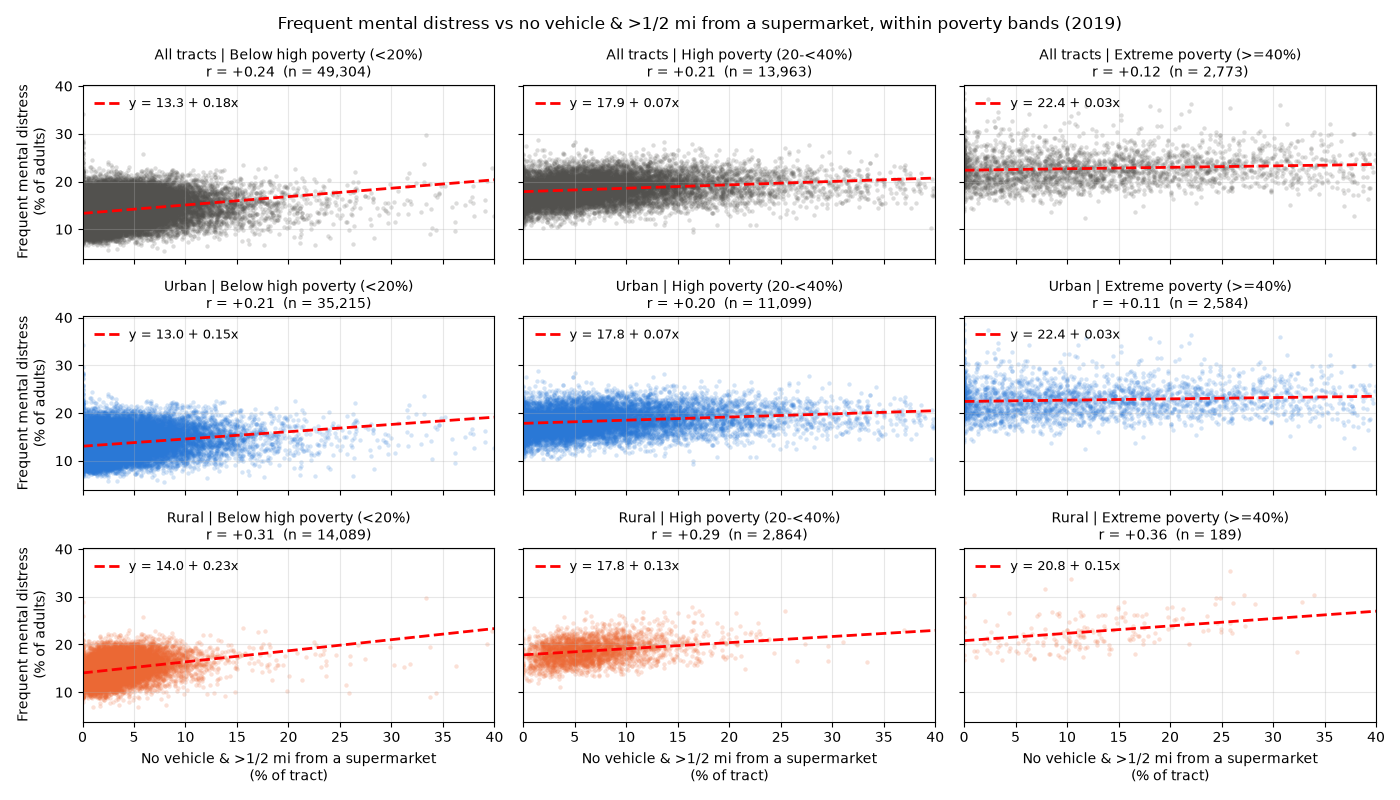

In [11]:
access_band_grid("lahunvhalfshare", "No vehicle & >1/2 mi from a supermarket")

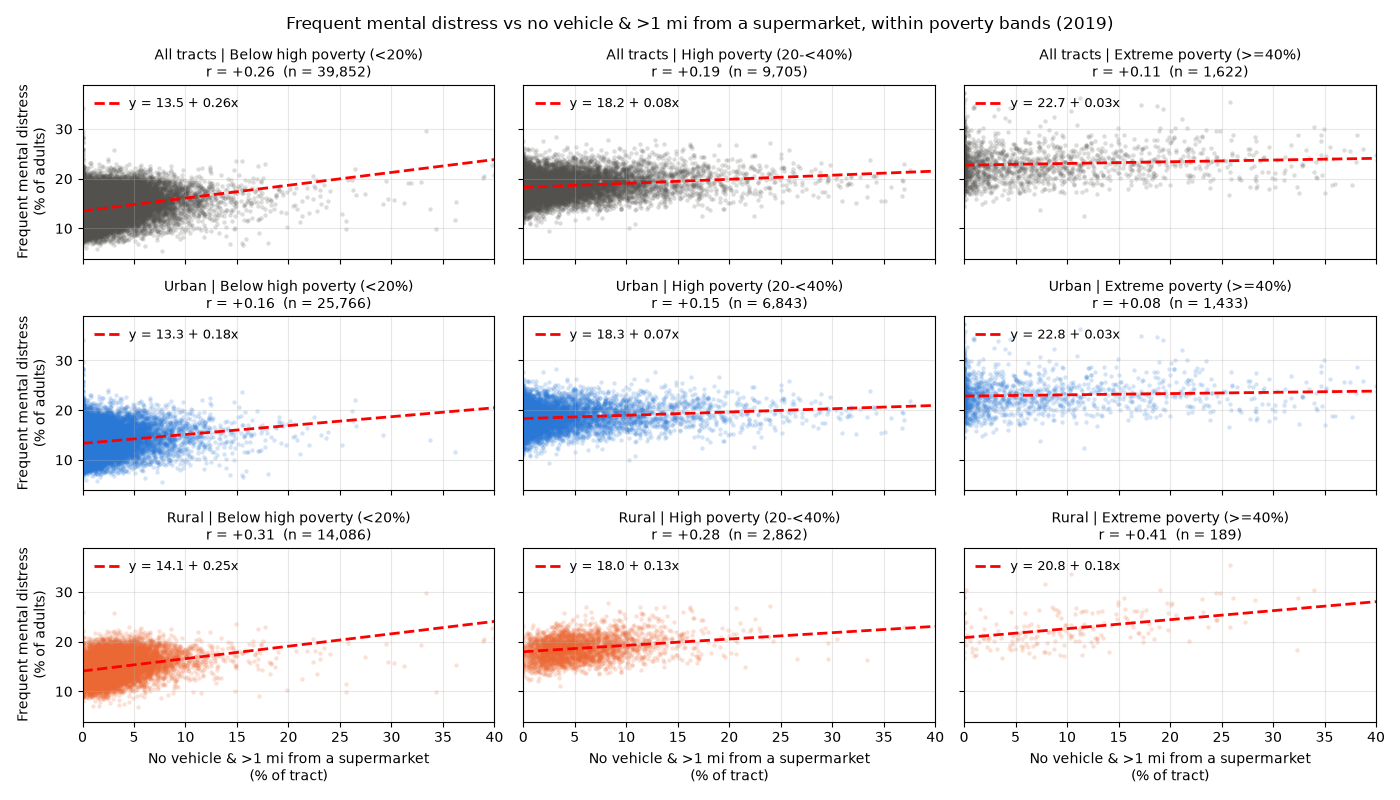

In [12]:
access_band_grid("lahunv1share", "No vehicle & >1 mi from a supermarket")

The poverty-band grids (rows: all, urban, rural; columns: the three poverty bands) answer the main question: does food access still relate to mental distress among tracts with similar poverty? The answer is yes, but less strongly, and mainly in rural and lower-poverty tracts.

1. The relationship weakens as poverty rises. The steepest slopes are in the below-high-poverty band and the flattest in extreme poverty. In the poorest urban tracts the line is almost flat (0.03): distress is high there regardless of access, as if poverty overwhelms everything else.

2. Rural tracts show the strongest, most consistent link. In every band the rural slope is steeper than the urban one, roughly double in the lower two bands. Without a car, being far from a store matters more in rural areas, where distances are longer and transit is scarce. That's research question 3.

Limited supermarket access was less closely linked to mental distress among neighborhoods in higher poverty bands. This means that differences in supermarket access lined up less consistently with differences in distress within those groups, even though distress was generally higher.

#### Miscellaneous

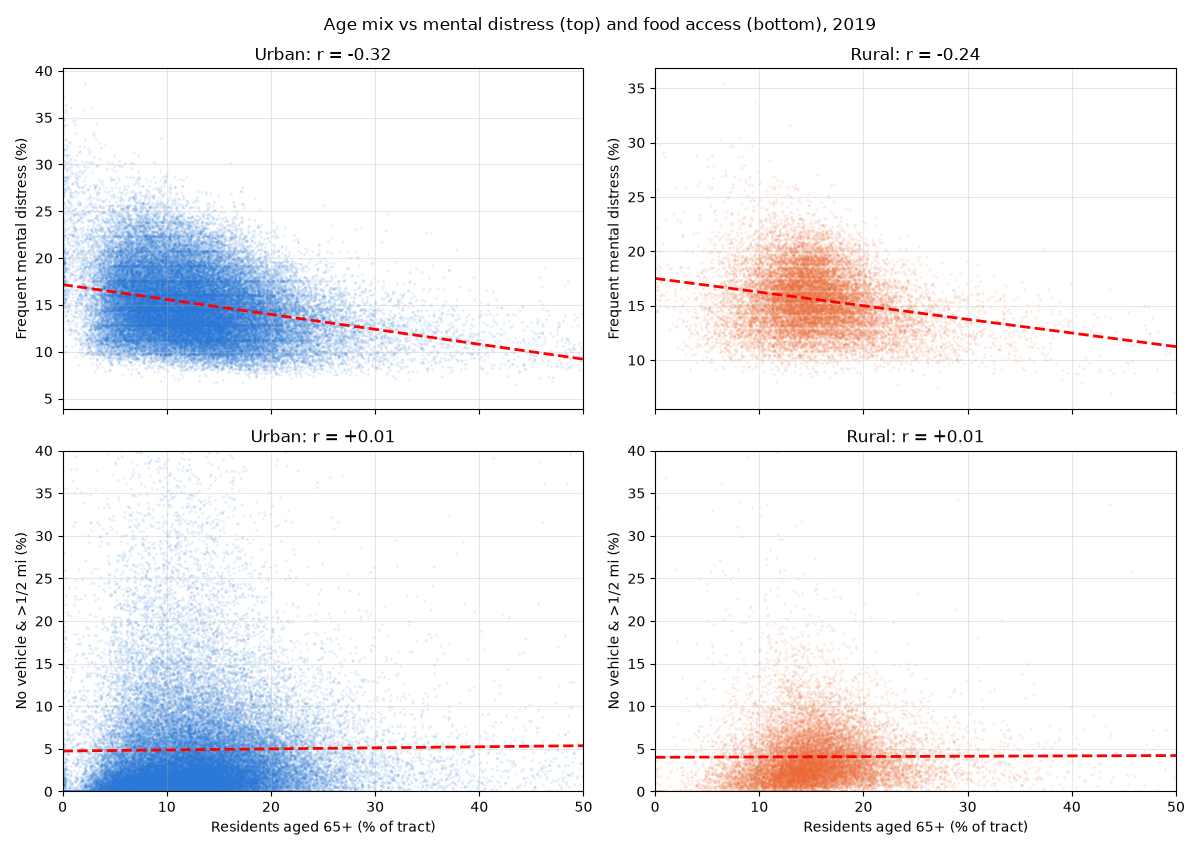

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

tracts["pct65"] = tracts["TractSeniors"] / tracts["Pop2010"] * 100     # % of residents aged 65+

colors = {"Urban": "#2a78d6", "Rural": "#eb6834"}
rows = [   # (y column, y-axis label, y-axis max)
    ("Data_Value", "Frequent mental distress (%)", None),
    ("lahunvhalfshare", "No vehicle & >1/2 mi (%)", 40),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharex=True)
for i, (y, ylabel, ymax) in enumerate(rows):
    for j, (area, color) in enumerate(colors.items()):
        ax = axes[i, j]
        s = tracts[tracts["Area"] == area].dropna(subset=["pct65", y])
        sns.scatterplot(data=s, x="pct65", y=y, color=color, s=4, alpha=0.12, linewidth=0, ax=ax)

        # Simple linear fit (least squares)
        slope, intercept = np.polyfit(s["pct65"], s[y], 1)
        xs = np.array([0, 50])
        ax.plot(xs, intercept + slope * xs, color="r", linewidth=2, linestyle="--")

        ax.set_title(f"{area}: r = {s['pct65'].corr(s[y]):+.2f}")
        ax.set_xlim(0, 50)
        ax.set_ylabel(ylabel)
        if ymax:
            ax.set_ylim(0, ymax)
        if i == 1:
            ax.set_xlabel("Residents aged 65+ (% of tract)")
        ax.grid(True, alpha=0.3)

fig.suptitle("Age mix vs mental distress (top) and food access (bottom), 2019")
fig.tight_layout()
plt.show()


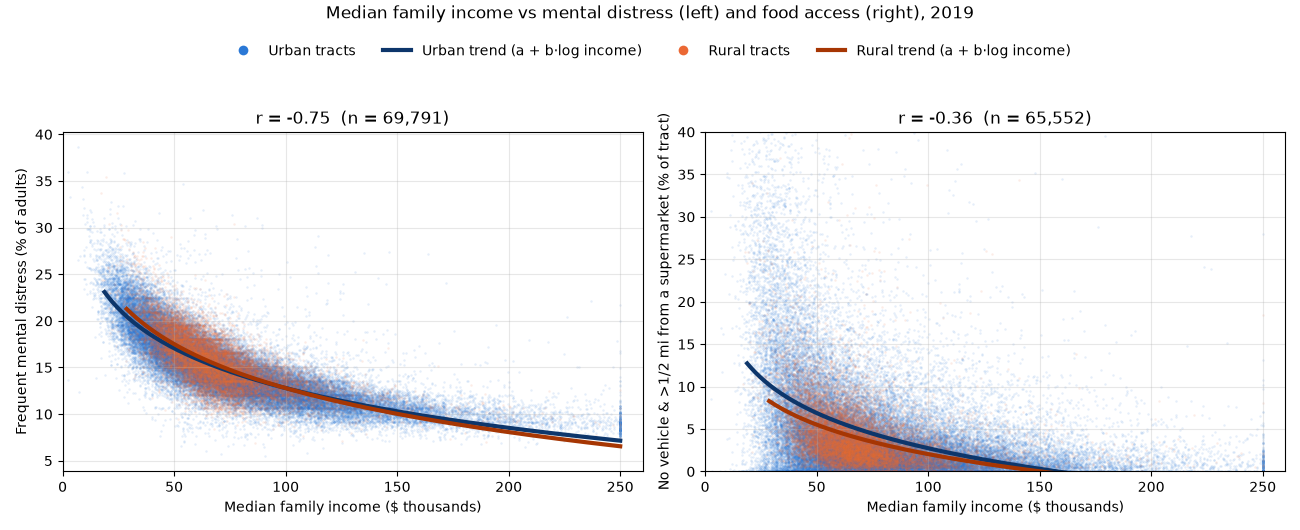

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

areas = {   # area: (point color, trend line color = darker shade)
    "Urban": ("#2a78d6", "#0d366b"),
    "Rural": ("#eb6834", "#a63603"),
}
panels = [   # (y column, y-axis label, y-axis max)
    ("Data_Value", "Frequent mental distress (% of adults)", None),
    ("lahunvhalfshare", "No vehicle & >1/2 mi from a supermarket (% of tract)", 40),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.3))
for ax, (y, ylabel, ymax) in zip(axes, panels):
    d = tracts.dropna(subset=["MedianFamilyIncome", y]).copy()
    d["income_k"] = d["MedianFamilyIncome"] / 1000
    for area, (color, line_color) in areas.items():
        s = d[d["Area"] == area]
        ax.scatter(s["income_k"], s[y], s=3, alpha=0.12, color=color, linewidths=0, rasterized=True)

        # Non-linear trend: y = a + b * log(income), fitted by least squares
        b, a = np.polyfit(np.log(s["income_k"]), s[y], 1)
        xs = np.linspace(s["income_k"].quantile(0.005), s["income_k"].max(), 200)
        ax.plot(xs, a + b * np.log(xs), color=line_color, linewidth=3)

    ax.set(xlabel="Median family income ($ thousands)", ylabel=ylabel, xlim=(0, 260),
           title=f"r = {d['income_k'].corr(d[y]):+.2f}  (n = {len(d):,})")
    if ymax:
        ax.set_ylim(0, ymax)
    ax.grid(True, alpha=0.3)

# Shared legend above both panels: tract dots and trend lines as separate entries
handles = []
for area, (pt, line) in areas.items():
    handles.append(Line2D([], [], marker="o", linestyle="", markerfacecolor=pt, markeredgewidth=0,
                          markersize=7, label=f"{area} tracts"))
    handles.append(Line2D([], [], color=line, linewidth=3, label=f"{area} trend (a + b·log income)"))
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.94))
fig.suptitle("Median family income vs mental distress (left) and food access (right), 2019", y=0.99)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()
